In [2]:
import os, gc, time, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
import rasterio.transform
from rasterio.warp import transform as warp_transform
from scipy import ndimage
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA_ROOT       = Path("/home/23CSU413/Deep Learning/AgriFieldNet")
SOURCE_DIR      = DATA_ROOT / "source"
TRAIN_LABEL_DIR = DATA_ROOT / "train_labels" / "train_labels"
TEST_LABEL_DIR  = DATA_ROOT / "test_labels"
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)

BANDS = ["B01","B02","B03","B04","B05","B06","B07","B08","B8A","B09","B11","B12"]
CROP_MAP = {1:"Wheat",2:"Mustard",3:"Lentil",4:"Fallow",5:"GreenPea",6:"Sugarcane",
            8:"Garlic",9:"Maize",13:"Gram",14:"Coriander",15:"Potato",16:"Berseem",36:"Rice"}
ORIG_LABELS = sorted(CROP_MAP)
LABEL2IDX   = {c: i for i, c in enumerate(ORIG_LABELS)}
CLASS_NAMES = [CROP_MAP[c] for c in ORIG_LABELS]
K = len(ORIG_LABELS)          # 13 classes
PATCH = 32                    # CNN patch size
USE_LOCATION = True           # use field lon/lat as features (set False to test without)

def chip_ids_from(folder):
    return sorted({p.stem.split("_")[-3] for p in folder.glob("*_field_ids.tif")})

all_chip_ids   = sorted(p.name.split("_")[-1] for p in SOURCE_DIR.iterdir() if p.is_dir())
train_chip_ids = chip_ids_from(TRAIN_LABEL_DIR)
test_chip_ids  = chip_ids_from(TEST_LABEL_DIR)
print("source chips:", len(all_chip_ids), "| train-label chips:", len(train_chip_ids),
      "| test-label chips:", len(test_chip_ids))

source chips: 1217 | train-label chips: 1165 | test-label chips: 707


In [3]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from scipy.ndimage import median_filter

TS_DIR = CACHE / "ts_fast"
USE_LOCATION = globals().get("USE_LOCATION", True)
cmap = dict(enumerate(CLASS_NAMES))
key = ["split", "field_id"]

pix = pd.read_pickle(CACHE / "pixels.pkl")
def nd(a, b): return (a - b) / (a + b + 1e-6)
pix["NDVI"] = nd(pix["B08"], pix["B04"]);  pix["GNDVI"] = nd(pix["B08"], pix["B03"])
pix["NDWI"] = nd(pix["B03"], pix["B08"]);  pix["NDMI"]  = nd(pix["B08"], pix["B11"])
pix["NBR"]  = nd(pix["B08"], pix["B12"]);  pix["NDRE"]  = nd(pix["B08"], pix["B05"])
pix["CIre"] = pix["B07"] / (pix["B05"] + 1e-6) - 1
pix["MSI"]  = pix["B11"] / (pix["B08"] + 1e-6)
pix["BSI"]  = nd(pix["B11"] + pix["B04"], pix["B08"] + pix["B02"])
SNAP_BASE = BANDS + ["NDVI", "GNDVI", "NDWI", "NDMI", "NBR", "NDRE", "CIre", "MSI", "BSI"]

geo = pix.groupby(key).agg(area=("B08", "size"), n_core=("core", "sum"), lon=("lon", "mean"),
                           lat=("lat", "mean"), label=("label", "max")).reset_index()
geo["log_area"] = np.log1p(geo["area"]); geo["edge_ratio"] = 1 - geo["n_core"] / geo["area"]
g = pix[pix["core"]].groupby(key)[SNAP_BASE]
snap = pd.concat([g.mean().add_suffix("_mean"), g.std().fillna(0).add_suffix("_std"),
                  g.median().add_suffix("_p50")], axis=1).reset_index()
fields = geo.merge(snap, on=key, how="left")

SNAP_COLS = [c for c in snap.columns if c not in key]
GEO_COLS = ["log_area", "edge_ratio"] + (["lon", "lat"] if USE_LOCATION else [])
ftr = fields[fields.split == "train"].reset_index(drop=True); ftr["label"] = ftr["label"].astype(int)
fte = fields[fields.split == "test"].reset_index(drop=True)

# ---- leak-free folds (same logic and seed as before): fields/chips that touch are one group ----
pairs = pix.loc[pix.split == "train", ["field_id", "chip_id"]].drop_duplicates()
parent = {}
def find(a):
    parent.setdefault(a, a)
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for fid, cid in zip(pairs.field_id.values, pairs.chip_id.values):
    ra, rb = find(f"f{fid}"), find(f"c{cid}")
    if ra != rb: parent[ra] = rb
ftr["group"] = pd.factorize([find(f"f{fid}") for fid in ftr.field_id])[0]
ftr["fold"] = -1
for k, (_, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(ftr, ftr.label, ftr.group)):
    ftr.loc[va, "fold"] = k
print("train fields:", len(ftr), "| test fields:", len(fte), "| fold sizes:", ftr.fold.value_counts().sort_index().tolist())

train fields: 5551 | test fields: 1530 | fold sizes: [1256, 1197, 982, 1010, 1106]


In [4]:
assert len(list(TS_DIR.glob("*.pkl"))) == len(all_chip_ids), "time-series cache incomplete: run notebook 02 first"
frames = [pd.read_pickle(p) for p in TS_DIR.glob("*.pkl")]
ts = pd.concat([f for f in frames if len(f)], ignore_index=True)
print("rows:", ts.shape, "| chips with data:", ts.chip_id.nunique(), "/", len(all_chip_ids))

S2V = ["B03", "B04", "B08", "B11", "NDVI", "NDMI", "NDWI"]
S1V = ["VV", "VH"]

def merge_sensor(df, cols, min_valid):
    """Combine the same field seen in 2 chips: weighted by number of valid pixels."""
    d = df[df.n_valid >= min_valid][["split", "field_id", "date", "n_valid"] + cols].copy()
    w = d["n_valid"].astype(float)
    for c in cols: d[c] = d[c] * w
    g = d.groupby(["split", "field_id", "date"])
    return g[cols].sum().div(g["n_valid"].sum(), axis=0).reset_index()

s2m = merge_sensor(ts[ts.sensor == "s2"], S2V, 3)
s1m = merge_sensor(ts[ts.sensor == "s1"], S1V, 1)
print("S2 field-dates:", len(s2m), "| S1 field-dates:", len(s1m))

rows: (271974, 16) | chips with data: 1212 / 1217
S2 field-dates: 121635 | S1 field-dates: 136694


In [5]:
GRID = np.arange(0, 243, 10); T = len(GRID)               # 1 Oct 2021 -> 31 May 2022, every 10 days
T0 = pd.Timestamp("2021-10-01")
allf = fields[key].reset_index(drop=True)
fidx = {(s, f): i for i, (s, f) in enumerate(zip(allf.split, allf.field_id))}

def build_cube(df, cols):
    cube = np.full((len(allf), T, len(cols)), np.nan, np.float32)
    nobs = np.zeros(len(allf), np.int32)
    df = df.copy(); df["day"] = (pd.to_datetime(df["date"]) - T0).dt.days
    df = df.sort_values(["split", "field_id", "day"])
    for (s, f), g in df.groupby(["split", "field_id"], sort=False):
        i = fidx.get((s, f))
        if i is None: continue
        d = g["day"].values; nobs[i] = len(d)
        for j, c in enumerate(cols): cube[i, :, j] = np.interp(GRID, d, g[c].values)
    return cube, nobs

C2, n2 = build_cube(s2m, S2V)
C1, n1 = build_cube(s1m, S1V)
has2 = n2 > 0
C2[has2] = median_filter(C2[has2], size=(1, 3, 1), mode="nearest")   # removes single-date cloud spikes
for C in (C2, C1):                                                    # fields with no data -> median curve
    med = np.nanmedian(C, axis=0); miss = np.isnan(C)
    C[miss] = np.broadcast_to(med, C.shape)[miss]

print("S2 valid dates per field:", pd.Series(n2).describe().round(1).to_dict())
print("share with >=8 S2 dates:", round((n2 >= 8).mean(), 3), "| >=8 S1 dates:", round((n1 >= 8).mean(), 3),
      "| fields with 0 S2:", int((n2 == 0).sum()), "| 0 S1:", int((n1 == 0).sum()))
print("NDVI range:", np.round(np.percentile(C2[:, :, S2V.index("NDVI")], [1, 50, 99]), 2))
np.save(CACHE / "cube_s2.npy", C2); np.save(CACHE / "cube_s1.npy", C1)
allf.to_pickle(CACHE / "cube_index.pkl")                              # for the deep-learning step later

S2 valid dates per field: {'count': 7081.0, 'mean': 17.2, 'std': 2.8, 'min': 0.0, '25%': 16.0, '50%': 17.0, '75%': 19.0, 'max': 23.0}
share with >=8 S2 dates: 0.986 | >=8 S1 dates: 0.979 | fields with 0 S2: 49 | 0 S1: 99
NDVI range: [0.11 0.42 0.87]


In [6]:
feat = {}
def add(name, arr): feat["ts_" + name] = np.asarray(arr, dtype=np.float32)

# raw curves
for j, v in enumerate(S2V):
    for t in range(T): add(f"{v}_t{t:02d}", C2[:, t, j])
for j, v in enumerate(S1V):
    for t in range(T): add(f"{v}_t{t:02d}", C1[:, t, j])
for t in range(T): add(f"VHVV_t{t:02d}", C1[:, t, 1] - C1[:, t, 0])

# summary statistics of each curve
def curve_stats(C, name):
    add(f"{name}_max", C.max(1));   add(f"{name}_min", C.min(1))
    add(f"{name}_mean", C.mean(1)); add(f"{name}_std", C.std(1))
    add(f"{name}_dmax", GRID[C.argmax(1)]); add(f"{name}_dmin", GRID[C.argmin(1)])
for j, v in enumerate(S2V): curve_stats(C2[:, :, j], v)
for j, v in enumerate(S1V): curve_stats(C1[:, :, j], v)

# phenology features from NDVI
nv = C2[:, :, S2V.index("NDVI")]
dnv = np.diff(nv, axis=1)
add("NDVI_amp", nv.max(1) - nv.min(1))
add("NDVI_auc", nv.sum(1) * 10)
add("NDVI_maxrise", dnv.max(1)); add("NDVI_maxfall", dnv.min(1))
add("NDVI_early", nv[:, :8].mean(1)); add("NDVI_mid", nv[:, 8:16].mean(1)); add("NDVI_late", nv[:, 16:].mean(1))
for thr in (0.3, 0.5):
    m = nv > thr
    add(f"NDVI_first_gt{thr}", np.where(m.any(1), GRID[m.argmax(1)], 999))
    add(f"NDVI_last_gt{thr}",  np.where(m.any(1), GRID[T - 1 - m[:, ::-1].argmax(1)], -1))
    add(f"NDVI_days_gt{thr}",  m.sum(1) * 10)
add("n_obs_s2", n2); add("n_obs_s1", n1)

TS_COLS = list(feat.keys())
TSdf = pd.concat([allf.reset_index(drop=True), pd.DataFrame(feat)], axis=1)

# safe to re-run: drop any earlier ts_ columns before merging
ftr = ftr.drop(columns=[c for c in ftr.columns if c.startswith("ts_")])
fte = fte.drop(columns=[c for c in fte.columns if c.startswith("ts_")])
n_tr, n_te = len(ftr), len(fte)
ftr = ftr.merge(TSdf, on=key, how="left"); fte = fte.merge(TSdf, on=key, how="left")
assert len(ftr) == n_tr and len(fte) == n_te, "merge changed the number of rows"
TSdf.to_pickle(CACHE / "ts_features.pkl")
print("time-series features:", len(TS_COLS), "| NaNs in train:", int(ftr[TS_COLS].isna().sum().sum()),
      "| train:", ftr.shape, "| test:", fte.shape)

time-series features: 319 | NaNs in train: 0 | train: (5551, 393) | test: (1530, 391)


In [7]:
y = ftr.label.values.astype(int); N = len(ftr)
FOLDS = [(np.where(ftr.fold != k)[0], np.where(ftr.fold == k)[0]) for k in range(5)]
prior = np.bincount(y, minlength=K) / N
SUMMARY, OOF = {}, {}

def soft_weights(y_, power=0.5):
    cnt = np.bincount(y_, minlength=K).astype(float); cnt[cnt == 0] = 1
    cw = (cnt.sum() / (K * cnt)) ** power
    return cw / cw[y_].mean()
def expand(p, classes):
    out = np.zeros((p.shape[0], K)); out[:, classes] = p; return out
def metrics(yt, yp):
    return dict(Accuracy=accuracy_score(yt, yp), BalancedAcc=balanced_accuracy_score(yt, yp),
                MacroF1=f1_score(yt, yp, average="macro"), WeightedF1=f1_score(yt, yp, average="weighted"))
def run_cv(name, fit_predict):
    oof = np.zeros((N, K)); t0 = time.time()
    for k, (tr, va) in enumerate(FOLDS): oof[va] = fit_predict(tr, va)
    OOF[name] = oof; SUMMARY[name] = metrics(y, oof.argmax(1))
    print(f"{name:42s}" + "  ".join(f"{a}={b:.3f}" for a, b in SUMMARY[name].items()) + f"  ({time.time()-t0:.0f}s)")

def make_rf(cols):
    X = ftr[cols].values.astype(np.float32)
    def fp(tr, va):
        cw = soft_weights(y[tr])
        m = RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=SEED)
        m.fit(X[tr], y[tr], sample_weight=cw[y[tr]])
        return expand(m.predict_proba(X[va]), m.classes_)
    return fp
def make_hgb(cols):
    X = ftr[cols].values.astype(np.float32)
    def fp(tr, va):
        cw = soft_weights(y[tr])
        m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=15,
                                           min_samples_leaf=10, l2_regularization=1.0, random_state=SEED)
        m.fit(X[tr], y[tr], sample_weight=cw[y[tr]])
        return expand(m.predict_proba(X[va]), m.classes_)
    return fp

FSETS = {"Snapshot only": SNAP_COLS + GEO_COLS,
         "Time-series only": TS_COLS + GEO_COLS,
         "Snapshot + time-series": SNAP_COLS + TS_COLS + GEO_COLS}

In [8]:
import os
from threadpoolctl import threadpool_limits
_lim = threadpool_limits(limits=min(8, os.cpu_count() or 4))     # cap OpenMP/BLAS threads
print("cores visible:", os.cpu_count(), "| thread cap:", min(8, os.cpu_count() or 4))

SUMMARY = globals().get("SUMMARY", {}); OOF = globals().get("OOF", {})

# ---- 1) the important comparison: RF on three feature sets (skips finished ones) ----
for name, cols in FSETS.items():
    tag = f"RF   | {name}"
    if tag in SUMMARY: print("already done:", tag); continue
    run_cv(tag, make_rf(cols))

# ---- 2) boosting: time 10 trees on one fold first, run only if the estimate is acceptable ----
cols = FSETS["Time-series only"]
Xt = ftr[cols].values.astype(np.float32); tr0, va0 = FOLDS[0]
t0 = time.time()
HistGradientBoostingClassifier(max_iter=10, learning_rate=0.08, max_leaf_nodes=15, random_state=SEED
                              ).fit(Xt[tr0], y[tr0], sample_weight=soft_weights(y[tr0])[y[tr0]])
est = (time.time() - t0) * 15 * 5
print(f"HGB timing test: 10 iterations took {time.time()-t0:.1f}s -> estimated {est/60:.1f} min per feature set (150 iters x 5 folds)")
RUN_HGB = est < 600
print("Running HGB" if RUN_HGB else "Skipping HGB (too slow on this server); RF results are enough for the comparison")

if RUN_HGB:
    for name, cols in FSETS.items():
        tag = f"HGB  | {name}"
        if tag in SUMMARY: continue
        run_cv(tag, make_hgb(cols))

cores visible: 24 | thread cap: 8
RF   | Snapshot only                      Accuracy=0.641  BalancedAcc=0.226  MacroF1=0.223  WeightedF1=0.604  (6s)
RF   | Time-series only                   Accuracy=0.724  BalancedAcc=0.304  MacroF1=0.324  WeightedF1=0.698  (9s)
RF   | Snapshot + time-series             Accuracy=0.729  BalancedAcc=0.315  MacroF1=0.335  WeightedF1=0.703  (10s)
HGB timing test: 10 iterations took 0.5s -> estimated 0.6 min per feature set (150 iters x 5 folds)
Running HGB
HGB  | Snapshot only                      Accuracy=0.648  BalancedAcc=0.250  MacroF1=0.254  WeightedF1=0.626  (15s)
HGB  | Time-series only                   Accuracy=0.738  BalancedAcc=0.333  MacroF1=0.348  WeightedF1=0.718  (32s)
HGB  | Snapshot + time-series             Accuracy=0.744  BalancedAcc=0.352  MacroF1=0.371  WeightedF1=0.727  (36s)


In [9]:
res = pd.DataFrame(SUMMARY).T.sort_values("MacroF1", ascending=False).round(4)
display(res); res.to_csv("ts_vs_snapshot_results.csv")

print("\nPer-class F1 (out-of-fold):")
f1tab = pd.DataFrame({n: f1_score(y, OOF[n].argmax(1), average=None, labels=list(range(K)), zero_division=0)
                      for n in OOF}, index=CLASS_NAMES).round(2)
print(f1tab.to_string())

best = res.index[0]; print("\nBest by macro-F1:", best)
print(classification_report(y, OOF[best].argmax(1), target_names=CLASS_NAMES, zero_division=0))

# prior correction on the best model (helps rare classes; trades a little accuracy)
prior = np.bincount(y, minlength=K) / N
rows = []
for a in np.arange(0, 0.81, 0.1):
    p = OOF[best] / (prior ** a)
    rows.append(dict(alpha=round(a, 1), **metrics(y, p.argmax(1))))
print("\nPrior correction on", best); print(pd.DataFrame(rows).round(3).to_string(index=False))

# which features matter
cols = FSETS["Snapshot + time-series"]
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)
rf.fit(ftr[cols].values.astype(np.float32), y, sample_weight=soft_weights(y)[y])
print("\nTop-20 features (snapshot + time-series RF):")
print(pd.Series(rf.feature_importances_, index=cols).sort_values(ascending=False).head(20).round(4))

,Accuracy,BalancedAcc,MacroF1,WeightedF1
HGB | Snapshot + time-series,0.7444,0.3522,0.3710,0.7266
HGB | Time-series only,0.7377,0.3332,0.3481,0.7181
RF | Snapshot + time-series,0.7289,0.3153,0.3352,0.7034
RF | Time-series only,0.7244,0.3041,0.3243,0.6980
HGB | Snapshot only,0.6478,0.2505,0.2539,0.6263
RF | Snapshot only,0.6408,0.2263,0.2231,0.6035



Per-class F1 (out-of-fold):
           RF   | Snapshot only  RF   | Time-series only  RF   | Snapshot + time-series  HGB  | Snapshot only  HGB  | Time-series only  HGB  | Snapshot + time-series
Wheat                      0.73                     0.80                           0.81                  0.73                     0.82                           0.82
Mustard                    0.39                     0.65                           0.65                  0.43                     0.64                           0.65
Lentil                     0.00                     0.00                           0.00                  0.02                     0.00                           0.08
Fallow                     0.75                     0.77                           0.78                  0.77                     0.81                           0.81
GreenPea                   0.00                     0.00                           0.00                  0.00                     0.00       

In [10]:
cols_noloc = [c for c in FSETS["Snapshot + time-series"] if c not in ("lon", "lat")]
run_cv("HGB  | Snapshot + time-series (no location)", make_hgb(cols_noloc))

HGB  | Snapshot + time-series (no location)Accuracy=0.740  BalancedAcc=0.342  MacroF1=0.364  WeightedF1=0.721  (36s)


In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
tf.keras.utils.set_random_seed(SEED)

# reload cubes if the kernel was restarted
if "C2" not in globals():
    C2 = np.load(CACHE / "cube_s2.npy"); C1 = np.load(CACHE / "cube_s1.npy")
    allf = pd.read_pickle(CACHE / "cube_index.pkl")
    fidx = {(s, f): i for i, (s, f) in enumerate(zip(allf.split, allf.field_id))}
T = C2.shape[1]

tr_i = np.array([fidx[("train", f)] for f in ftr.field_id])
te_i = np.array([fidx[("test", f)] for f in fte.field_id])
SEQ_ALL = np.concatenate([C2, C1, (C1[:, :, 1] - C1[:, :, 0])[:, :, None]], axis=2).astype(np.float32)
SEQ, SEQ_TE = SEQ_ALL[tr_i], SEQ_ALL[te_i]
ST_COLS = SNAP_COLS + GEO_COLS
ST = np.nan_to_num(ftr[ST_COLS].values.astype(np.float32)); ST_TE = np.nan_to_num(fte[ST_COLS].values.astype(np.float32))
NCH, NST = SEQ.shape[2], ST.shape[1]
print("sequence:", SEQ.shape, "| static:", ST.shape)

def _inputs():
    return layers.Input((T, NCH), name="seq"), layers.Input((NST,), name="st")

def _finish(seq, st, h):
    out = layers.Dense(K, activation="softmax")(h)
    m = models.Model({"seq": seq, "st": st}, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy")
    return m

def build_ann():
    seq, st = _inputs()
    x = layers.Concatenate()([layers.Flatten()(seq), st])
    for u, d in ((256, .3), (128, .3), (64, .2)):
        x = layers.Dense(u, activation="relu")(x); x = layers.BatchNormalization()(x); x = layers.Dropout(d)(x)
    return _finish(seq, st, x)

def build_cnn1d():
    seq, st = _inputs(); x = seq
    for f, pool in ((64, False), (64, True), (128, False), (128, False)):
        x = layers.Conv1D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        if pool: x = layers.MaxPooling1D(2)(x)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), layers.GlobalMaxPooling1D()(x)])
    x = layers.Concatenate()([layers.Dropout(0.3)(x), layers.Dense(64, activation="relu")(st)])
    x = layers.Dense(128, activation="relu")(x); x = layers.BatchNormalization()(x); x = layers.Dropout(0.4)(x)
    return _finish(seq, st, x)

class AddPos(layers.Layer):
    """Learned positional embedding for the 25 time steps."""
    def build(self, shape):
        self.pos = self.add_weight(shape=(shape[1], shape[2]), initializer="random_normal", trainable=True)
    def call(self, x): return x + self.pos

def build_transformer(d=64, heads=4, blocks=2):
    seq, st = _inputs()
    x = AddPos()(layers.Dense(d)(seq))
    for _ in range(blocks):
        a = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, dropout=0.1)(x, x)
        x = layers.LayerNormalization()(layers.Add()([x, a]))
        f = layers.Dense(2 * d, activation="gelu")(x); f = layers.Dropout(0.1)(layers.Dense(d)(f))
        x = layers.LayerNormalization()(layers.Add()([x, f]))
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Concatenate()([x, layers.Dense(64, activation="relu")(st)])
    x = layers.Dense(128, activation="relu")(x); x = layers.BatchNormalization()(x); x = layers.Dropout(0.3)(x)
    return _finish(seq, st, x)

def make_dl(builder, epochs=80):
    def fp(tr, va):
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
        rng = np.random.RandomState(SEED)
        inner = rng.choice(tr, size=int(0.1 * len(tr)), replace=False); fit = np.setdiff1d(tr, inner)
        smu, ssd = SEQ[fit].mean((0, 1), keepdims=True), SEQ[fit].std((0, 1), keepdims=True) + 1e-6
        tmu, tsd = ST[fit].mean(0, keepdims=True), ST[fit].std(0, keepdims=True) + 1e-6
        X = lambda ids: {"seq": ((SEQ[ids] - smu) / ssd).astype(np.float32),
                         "st": np.nan_to_num((ST[ids] - tmu) / tsd).astype(np.float32)}
        cw = soft_weights(y[fit])
        model = builder()
        cb = [callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
              callbacks.ReduceLROnPlateau(factor=0.5, patience=4)]
        model.fit(X(fit), y[fit], sample_weight=cw[y[fit]].astype(np.float32),
                  validation_data=(X(inner), y[inner], cw[y[inner]].astype(np.float32)),
                  epochs=epochs, batch_size=128, callbacks=cb, verbose=0)
        return model.predict(X(va), batch_size=512, verbose=0)
    return fp

2026-11-05 16:45:15.889696: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-05 16:45:15.911526: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16, in other operations, rebuild TensorFlow with the appropriate compiler flags.


sequence: (5551, 25, 10) | static: (5551, 67)


In [12]:
run_cv("ANN  | seq+static", make_dl(build_ann))
run_cv("CNN1D| seq+static", make_dl(build_cnn1d))
run_cv("Transformer | seq+static", make_dl(build_transformer))

ANN  | seq+static                         Accuracy=0.707  BalancedAcc=0.415  MacroF1=0.392  WeightedF1=0.712  (35s)
CNN1D| seq+static                         Accuracy=0.707  BalancedAcc=0.396  MacroF1=0.374  WeightedF1=0.705  (66s)
Transformer | seq+static                  Accuracy=0.687  BalancedAcc=0.369  MacroF1=0.361  WeightedF1=0.690  (138s)


In [13]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_svm(cols):
    X = np.nan_to_num(ftr[cols].values.astype(np.float32))
    def fp(tr, va):
        cw = soft_weights(y[tr])
        m = make_pipeline(StandardScaler(),
                          SVC(kernel="rbf", C=10, gamma="scale", probability=True,
                              cache_size=1000, random_state=SEED))
        m.fit(X[tr], y[tr], svc__sample_weight=cw[y[tr]])
        return expand(m.predict_proba(X[va]), m.classes_)
    return fp

run_cv("SVM  | Snapshot + time-series", make_svm(FSETS["Snapshot + time-series"]))

SVM  | Snapshot + time-series             Accuracy=0.723  BalancedAcc=0.329  MacroF1=0.347  WeightedF1=0.702  (62s)


In [14]:
ENS = [n for n in ["HGB  | Snapshot + time-series", "RF   | Snapshot + time-series",
                   "ANN  | seq+static", "CNN1D| seq+static", "Transformer | seq+static"] if n in OOF]
print("ensemble members:", ENS)
OOF["Ensemble"] = np.mean([OOF[n] for n in ENS], axis=0)
SUMMARY["Ensemble"] = metrics(y, OOF["Ensemble"].argmax(1))

prior = np.bincount(y, minlength=K) / N
rows = []
for a in np.arange(0, 0.91, 0.1):
    rows.append(dict(alpha=round(a, 1), **metrics(y, (OOF["Ensemble"] / prior ** a).argmax(1))))
tune = pd.DataFrame(rows); print(tune.round(3).to_string(index=False))

ensemble members: ['HGB  | Snapshot + time-series', 'RF   | Snapshot + time-series', 'ANN  | seq+static', 'CNN1D| seq+static', 'Transformer | seq+static']
 alpha  Accuracy  BalancedAcc  MacroF1  WeightedF1
   0.0     0.747        0.385    0.388       0.733
   0.1     0.744        0.408    0.403       0.736
   0.2     0.736        0.440    0.423       0.736
   0.3     0.718        0.454    0.415       0.727
   0.4     0.693        0.471    0.404       0.716
   0.5     0.652        0.475    0.383       0.693
   0.6     0.599        0.478    0.362       0.661
   0.7     0.540        0.496    0.345       0.619
   0.8     0.473        0.504    0.325       0.564
   0.9     0.391        0.486    0.297       0.485


,Accuracy,BalancedAcc,MacroF1,WeightedF1
Ensemble + prior corr.,0.7357,0.4399,0.4227,0.7359
ANN | seq+static,0.7067,0.4155,0.3916,0.7117
Ensemble,0.7467,0.3850,0.3880,0.7326
CNN1D| seq+static,0.7065,0.3962,0.3744,0.7048
HGB | Snapshot + time-series,0.7444,0.3522,0.3710,0.7266
HGB | Snapshot + time-series (no location),0.7395,0.3420,0.3640,0.7207
Transformer | seq+static,0.6874,0.3688,0.3608,0.6900
HGB | Time-series only,0.7377,0.3332,0.3481,0.7181
SVM | Snapshot + time-series,0.7233,0.3285,0.3469,0.7020
RF | Snapshot + time-series,0.7289,0.3153,0.3352,0.7034


              precision    recall  f1-score   support

       Wheat       0.83      0.83      0.83      2031
     Mustard       0.66      0.66      0.66       990
      Lentil       0.13      0.16      0.14       103
      Fallow       0.84      0.77      0.80      1641
    GreenPea       0.00      0.00      0.00        23
   Sugarcane       0.39      0.72      0.50       163
      Garlic       0.45      0.58      0.51        48
       Maize       0.68      0.82      0.75       293
        Gram       0.70      0.68      0.69        59
   Coriander       0.00      0.00      0.00        14
      Potato       0.17      0.12      0.14        41
     Berseem       0.18      0.12      0.15        16
        Rice       0.46      0.25      0.32       129

    accuracy                           0.74      5551
   macro avg       0.42      0.44      0.42      5551
weighted avg       0.74      0.74      0.74      5551



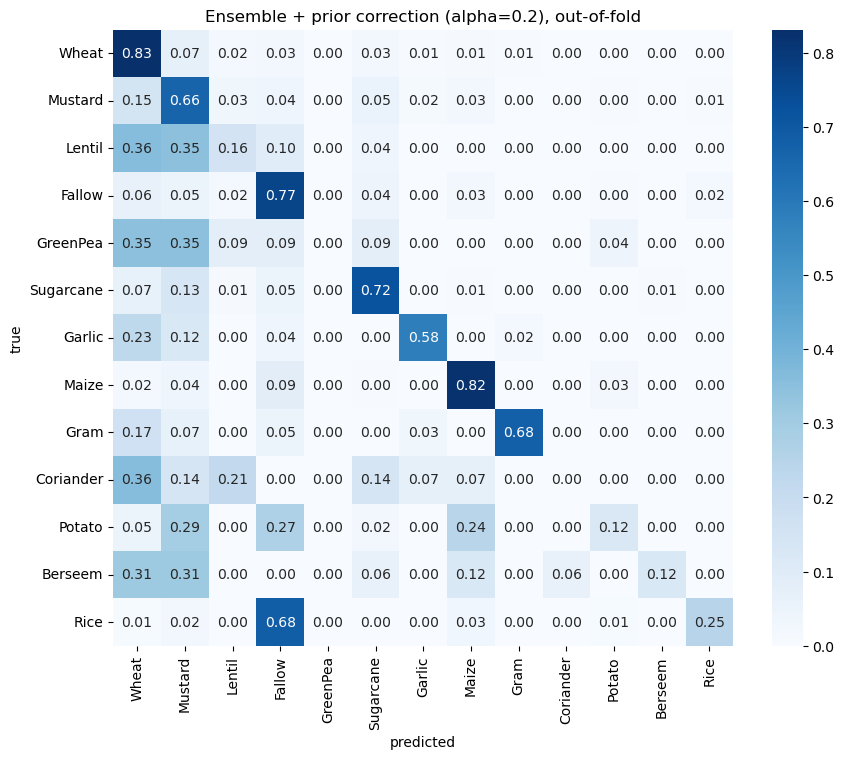

In [15]:
from sklearn.metrics import confusion_matrix
alpha = 0.2
OOF["Ensemble + prior corr."] = OOF["Ensemble"] / prior ** alpha
SUMMARY["Ensemble + prior corr."] = metrics(y, OOF["Ensemble + prior corr."].argmax(1))

res = pd.DataFrame(SUMMARY).T.sort_values("MacroF1", ascending=False).round(4)
display(res); res.to_csv("final_results.csv")

pred = OOF["Ensemble + prior corr."].argmax(1)
print(classification_report(y, pred, target_names=CLASS_NAMES, zero_division=0))
cm = confusion_matrix(y, pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Ensemble + prior correction (alpha=0.2), out-of-fold")
plt.show()

In [16]:
P = {}
cols_f = FSETS["Snapshot + time-series"]
Xs_tr = np.nan_to_num(ftr[cols_f].values.astype(np.float32))
Xs_te = np.nan_to_num(fte[cols_f].values.astype(np.float32))
cw_all = soft_weights(y)

hgb = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=15,
                                     min_samples_leaf=10, l2_regularization=1.0, random_state=SEED)
hgb.fit(Xs_tr, y, sample_weight=cw_all[y]); P["HGB"] = expand(hgb.predict_proba(Xs_te), hgb.classes_)
rf = RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=SEED)
rf.fit(Xs_tr, y, sample_weight=cw_all[y]); P["RF"] = expand(rf.predict_proba(Xs_te), rf.classes_)
print("tabular models done")

def dl_full(builder, seed):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    rng = np.random.RandomState(seed)
    inner = rng.choice(N, size=int(0.1 * N), replace=False); fit = np.setdiff1d(np.arange(N), inner)
    smu, ssd = SEQ[fit].mean((0, 1), keepdims=True), SEQ[fit].std((0, 1), keepdims=True) + 1e-6
    tmu, tsd = ST[fit].mean(0, keepdims=True), ST[fit].std(0, keepdims=True) + 1e-6
    prep = lambda s, t: {"seq": ((s - smu) / ssd).astype(np.float32),
                         "st": np.nan_to_num((t - tmu) / tsd).astype(np.float32)}
    cw = soft_weights(y[fit])
    model = builder()
    cb = [callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
          callbacks.ReduceLROnPlateau(factor=0.5, patience=4)]
    model.fit(prep(SEQ[fit], ST[fit]), y[fit], sample_weight=cw[y[fit]].astype(np.float32),
              validation_data=(prep(SEQ[inner], ST[inner]), y[inner], cw[y[inner]].astype(np.float32)),
              epochs=80, batch_size=128, callbacks=cb, verbose=0)
    return model.predict(prep(SEQ_TE, ST_TE), batch_size=512, verbose=0)

for name, builder in [("ANN", build_ann), ("CNN1D", build_cnn1d), ("Transformer", build_transformer)]:
    P[name] = np.mean([dl_full(builder, SEED + s) for s in range(3)], axis=0)
    print(name, "done")

ens_te = np.mean([P[k] for k in P], axis=0)
adj = ens_te / prior ** 0.2; adj /= adj.sum(1, keepdims=True)
sub = pd.DataFrame(adj, columns=CLASS_NAMES); sub.insert(0, "field_id", fte.field_id.values)
sub.insert(1, "pred_crop", [CLASS_NAMES[i] for i in adj.argmax(1)])
sub.to_csv("test_predictions_final.csv", index=False)

print(pd.DataFrame({"test_pred_%": (100 * sub.pred_crop.value_counts(normalize=True)).round(1),
                    "train_true_%": (100 * ftr.label.map(cmap).value_counts(normalize=True)).round(1)})
      .reindex(CLASS_NAMES).fillna(0))

tabular models done
ANN done
CNN1D done
Transformer done
           test_pred_%  train_true_%
Wheat             20.1          36.6
Mustard           15.4          17.8
Lentil             3.3           1.9
Fallow            25.0          29.6
GreenPea           0.1           0.4
Sugarcane         11.1           2.9
Garlic             2.5           0.9
Maize             13.7           5.3
Gram               2.7           1.1
Coriander          0.0           0.3
Potato             1.2           0.7
Berseem            0.5           0.3
Rice               4.4           2.3


In [17]:
import os, time
from threadpoolctl import threadpool_limits
_lim = threadpool_limits(limits=8)                     # the cap that was lost when the kernel restarted
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score

def mix(p): return pd.Series(100 * np.bincount(p.argmax(1), minlength=K) / len(p), index=CLASS_NAMES).round(1)
def new_hgb():
    return HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=15,
                                          min_samples_leaf=10, l2_regularization=1.0, random_state=SEED)

cols = FSETS["Snapshot + time-series"]
Xs_tr = np.nan_to_num(ftr[cols].values.astype(np.float32)); Xs_te = np.nan_to_num(fte[cols].values.astype(np.float32))

# timing test first: should take about 1 s
t0 = time.time()
new_hgb().set_params(max_iter=10).fit(Xs_tr[FOLDS[0][0]], y[FOLDS[0][0]])
print(f"10-iteration timing test: {time.time()-t0:.1f}s (expect about 1-2 s; if over 15 s, tell me)")

oof = np.zeros((N, K))
for k, (tr, va) in enumerate(FOLDS):
    t0 = time.time()
    m = new_hgb().fit(Xs_tr[tr], y[tr], sample_weight=soft_weights(y[tr])[y[tr]])
    oof[va] = expand(m.predict_proba(Xs_tr[va]), m.classes_)
    print(f"fold {k} done in {time.time()-t0:.0f}s")
m = new_hgb().fit(Xs_tr, y, sample_weight=soft_weights(y)[y])
p_te = expand(m.predict_proba(Xs_te), m.classes_)
np.save(CACHE / "hgb_oof.npy", oof); np.save(CACHE / "hgb_test.npy", p_te)
print("saved hgb_oof.npy and hgb_test.npy")

10-iteration timing test: 0.5s (expect about 1-2 s; if over 15 s, tell me)
fold 0 done in 7s
fold 1 done in 7s
fold 2 done in 7s
fold 3 done in 7s
fold 4 done in 7s
saved hgb_oof.npy and hgb_test.npy


In [18]:
tab = pd.DataFrame({"train_true": (100 * np.bincount(y, minlength=K) / N).round(1)}, index=CLASS_NAMES)
tab["HGB OOF a=0"]   = mix(oof)
tab["HGB OOF a=0.2"] = mix(oof / prior ** 0.2)
tab["HGB test a=0"]   = mix(p_te)
tab["HGB test a=0.2"] = mix(p_te / prior ** 0.2)
try:
    sub = pd.read_csv("test_predictions_final.csv")
    tab["saved CSV (ensemble a=0.2)"] = (100 * sub.pred_crop.value_counts(normalize=True)).reindex(CLASS_NAMES).fillna(0).round(1)
except FileNotFoundError:
    print("test_predictions_final.csv not found in this folder")
print(tab.to_string())

chk = ["ts_n_obs_s2", "ts_n_obs_s1", "log_area", "edge_ratio", "ts_NDVI_max", "ts_NDVI_mean", "ts_NDMI_mean", "lat", "lon"]
cmp = pd.DataFrame({"train_p10": ftr[chk].quantile(.1), "test_p10": fte[chk].quantile(.1),
                    "train_med": ftr[chk].median(),      "test_med": fte[chk].median(),
                    "train_p90": ftr[chk].quantile(.9), "test_p90": fte[chk].quantile(.9)})
print("\n", cmp.round(3).to_string())
print("\nfields with 0 S2 dates -> train:", round((ftr.ts_n_obs_s2 == 0).mean(), 3), "| test:", round((fte.ts_n_obs_s2 == 0).mean(), 3))
print("fields with 0 S1 dates -> train:", round((ftr.ts_n_obs_s1 == 0).mean(), 3), "| test:", round((fte.ts_n_obs_s1 == 0).mean(), 3))

# adversarial validation (AUC 0.5 = train and test fields are indistinguishable)
for label, cols_adv in [("with location", cols), ("without location", [c for c in cols if c not in ("lat", "lon")])]:
    t0 = time.time()
    Xa = np.nan_to_num(np.vstack([ftr[cols_adv].values, fte[cols_adv].values]).astype(np.float32))
    ya = np.r_[np.zeros(len(ftr)), np.ones(len(fte))]
    rfa = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED)
    pa = cross_val_predict(rfa, Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    print(f"\nAdversarial AUC ({label}): {roc_auc_score(ya, pa):.3f}  ({time.time()-t0:.0f}s)")
    rfa.fit(Xa, ya)
    print(pd.Series(rfa.feature_importances_, index=cols_adv).sort_values(ascending=False).head(6).round(3).to_string())

           train_true  HGB OOF a=0  HGB OOF a=0.2  HGB test a=0  HGB test a=0.2  saved CSV (ensemble a=0.2)
Wheat            36.6         40.2           39.2          24.5            23.2                        20.1
Mustard          17.8         19.0           19.3          18.8            18.4                        15.4
Lentil            1.9          0.3            0.6           0.5             1.1                         3.3
Fallow           29.6         30.1           29.3          29.5            28.2                        25.0
GreenPea          0.4          0.0            0.0           0.0             0.1                         0.1
Sugarcane         2.9          2.8            3.4           5.5             6.3                        11.1
Garlic            0.9          0.5            0.6           1.7             2.0                         2.5
Maize             5.3          5.9            6.0          13.1            13.3                        13.7
Gram              1.1       

In [19]:
pred = OOF["Ensemble + prior corr."].argmax(1); ok = (pred == y)
d = pd.DataFrame({"ok": ok, "area": ftr["area"].values, "label": y})
d["size_bin"] = pd.qcut(d["area"], 5, duplicates="drop")
print(d.groupby("size_bin").agg(n=("ok", "size"), accuracy=("ok", "mean")).round(3))

idx = [CLASS_NAMES.index(c) for c in ["Wheat", "Mustard", "Fallow"]]
big3 = d.label.isin(idx)
print("share of all errors from Wheat/Mustard/Fallow:", round((~d.ok & big3).sum() / (~d.ok).sum(), 3))
print("accuracy if every OTHER class were perfect:", round((d.ok | ~big3).mean(), 3))
m = np.isin(y, idx)
print(pd.crosstab(pd.Series(y[m]).map(cmap), pd.Series(pred[m]).map(cmap)))

                  n  accuracy
size_bin                     
(0.999, 12.0]  1192     0.689
(12.0, 19.0]   1119     0.696
(19.0, 28.0]   1082     0.739
(28.0, 46.0]   1065     0.757
(46.0, 575.0]  1093     0.803
share of all errors from Wheat/Mustard/Fallow: 0.723
accuracy if every OTHER class were perfect: 0.809
col_0    Berseem  Coriander  Fallow  Garlic  Gram  GreenPea  Lentil  Maize  \
row_0                                                                        
Fallow         1          1    1258       3     2         1      30     46   
Mustard        3          2      39      15     3         2      34     25   
Wheat          4          2      51      13    11         0      37     22   

col_0    Mustard  Potato  Rice  Sugarcane  Wheat  
row_0                                             
Fallow        85       8    32         71    103  
Mustard      656       4     6         52    149  
Wheat        148       2     0         53   1688  


In [20]:
ART = Path("artifacts"); ART.mkdir(exist_ok=True)

keys = list(OOF)
np.savez_compressed(ART / "oof_probs.npz", **{f"m{i}": OOF[k] for i, k in enumerate(keys)})
json.dump(keys, open(ART / "oof_keys.json", "w"))
json.dump(list(CLASS_NAMES), open(ART / "class_names.json", "w"))
json.dump({"alpha": 0.2, "prior": prior.tolist()}, open(ART / "prior.json", "w"))

ftr.to_pickle(ART / "ftr.pkl"); fte.to_pickle(ART / "fte.pkl")   # features, labels, fold
np.save(ART / "SEQ.npy", SEQ); np.save(ART / "SEQ_TE.npy", SEQ_TE)
json.dump(list(ST_COLS), open(ART / "st_cols.json", "w"))
print("saved:", sorted(p.name for p in ART.iterdir()))

saved: ['SEQ.npy', 'SEQ_TE.npy', 'class_names.json', 'fte.pkl', 'ftr.pkl', 'oof_keys.json', 'oof_probs.npz', 'prior.json', 'st_cols.json']
